In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans as km
from sklearn.cluster import DBSCAN as bd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score as ss
from sklearn.neighbors import NearestNeighbors


In [54]:
df = pd.read_csv("/content/Online Retail.csv")

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [56]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [57]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [58]:
df = df.dropna(subset=["CustomerID"])

In [59]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    406829 non-null  object 
 1   StockCode    406829 non-null  object 
 2   Description  406829 non-null  object 
 3   Quantity     406829 non-null  int64  
 4   InvoiceDate  406829 non-null  object 
 5   UnitPrice    406829 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      406829 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 27.9+ MB


In [61]:
df.drop_duplicates(inplace=True)

In [62]:
df = df[(df['Quantity']>0) & (df['UnitPrice']>0)&(df['InvoiceNo'].astype(str).str[0] != 'C')].copy()

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  object 
 1   StockCode    392692 non-null  object 
 2   Description  392692 non-null  object 
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  object 
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  float64
 7   Country      392692 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 27.0+ MB


In [64]:
df['Revenue'] = df['Quantity']*df['UnitPrice']

In [65]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%d-%m-%Y %H:%M')

In [66]:
snapshot_date = df['InvoiceDate'].max()+pd.Timedelta(days = 1)


In [67]:
rfm = df.groupby('CustomerID').agg(
    LastPur = ("InvoiceDate", "max"),
    Freq = ("InvoiceNo", "nunique"),
    Monetary = ("Revenue", "sum")
).reset_index()
rfm["recency"] = (snapshot_date - rfm["LastPur"]).dt.days

In [68]:
rfm_features = rfm[["recency", "Freq", "Monetary"]]

In [69]:
rfm_features.skew()

,0
recency,1.246048
Freq,12.067031
Monetary,19.339368


In [70]:
rfm_log = np.log1p(rfm_features)

In [71]:
rfm_log.skew()

,0
recency,-0.379169
Freq,1.208652
Monetary,0.396599


In [72]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

---
###ELBOW METHOD


[]

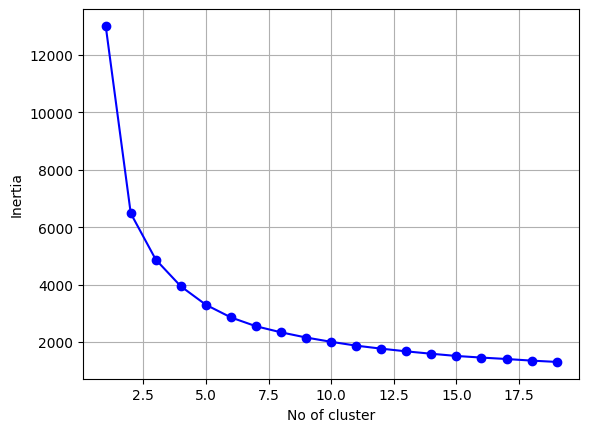

In [73]:
inertia = []
k_range = range(1,20)
for k in k_range:
  kmeans = km(n_clusters = k, n_init = 10, random_state = 42)
  kmeans.fit(rfm_scaled)
  inertia.append(kmeans.inertia_)


plt.figure()
plt.plot(k_range,inertia, marker = 'o', color = 'b')
plt.xlabel("No of cluster")
plt.ylabel("Inertia")
plt.grid(True)
plt.plot()

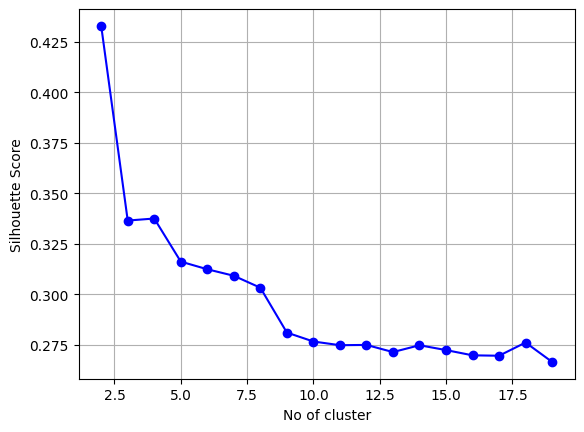

In [74]:

ss_score = []
k_range = range(2,20)
for k in k_range:
  kmeans_temp = km(n_clusters=k,n_init = 10, random_state = 42)
  cluster_labels = kmeans_temp.fit_predict(rfm_scaled)
  score = ss(rfm_scaled,cluster_labels)
  ss_score.append(score)

plt.figure()
plt.plot(k_range,ss_score, marker = 'o', color = 'b')
plt.xlabel("No of cluster")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

In [75]:
kmeans = km(n_clusters=5,n_init=10,random_state=42)
rfm["Kmeans_cluster"] = kmeans.fit_predict(rfm_scaled)
print("Kmeans cluster count: ", rfm['Kmeans_cluster'].value_counts())

Kmeans cluster count:  Kmeans_cluster
2    1209
3    1018
1     938
0     834
4     339
Name: count, dtype: int64


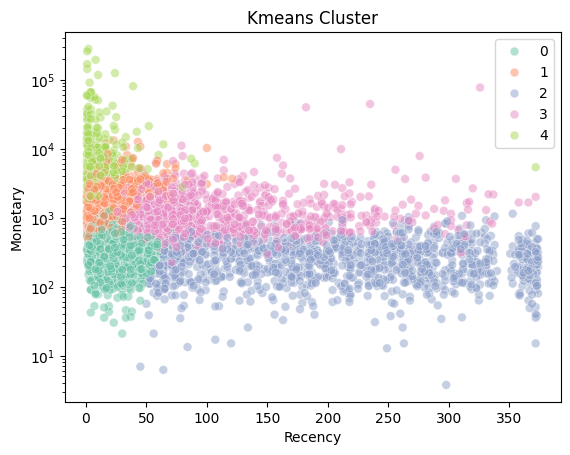

In [76]:
plt.figure()
sns.scatterplot(
    x = "recency",
    y = "Monetary",
    hue = "Kmeans_cluster",
    data = rfm,
    palette = "Set2",
    s = 40,
    alpha = 0.5
)
plt.legend(loc='upper right')
plt.yscale("log")
plt.xlabel("Recency")
plt.ylabel("Monetary")
plt.title("Kmeans Cluster")
plt.show()

---
###CUSTOMER PROFILE ANALYSIS

In [77]:
profile = rfm.groupby('Kmeans_cluster').agg(
    recency = ('recency', 'mean'),
    freq = ('Freq', 'mean'),
    monetary = ('Monetary', 'mean'),
    cout =  ("CustomerID", 'count'),
    total_revenue = ("Monetary", "sum"),
).round(1)

In [78]:
profile["Revenu_Share"] = (profile['total_revenue']/profile['total_revenue'].sum() *100).round(3)
profile

,recency,freq,monetary,cout,total_revenue,Revenu_Share
Kmeans_cluster,,,,,,
0,27.0,1.6,389.6,834,324908.2,3.656
1,18.5,5.8,2179.4,938,2044281.5,23.003
2,208.4,1.2,277.2,1209,335158.6,3.771
3,103.7,3.1,1452.4,1018,1478503.4,16.636
4,12.2,20.7,13877.2,339,4704357.2,52.934


/tmp/ipykernel_2669/3312829971.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x =profile.index, y = profile[cols], palette='Set2', ax = ax)
/tmp/ipykernel_2669/3312829971.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x =profile.index, y = profile[cols], palette='Set2', ax = ax)
/tmp/ipykernel_2669/3312829971.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x =profile.index, y = profile[cols], palette='Set2', ax = ax)


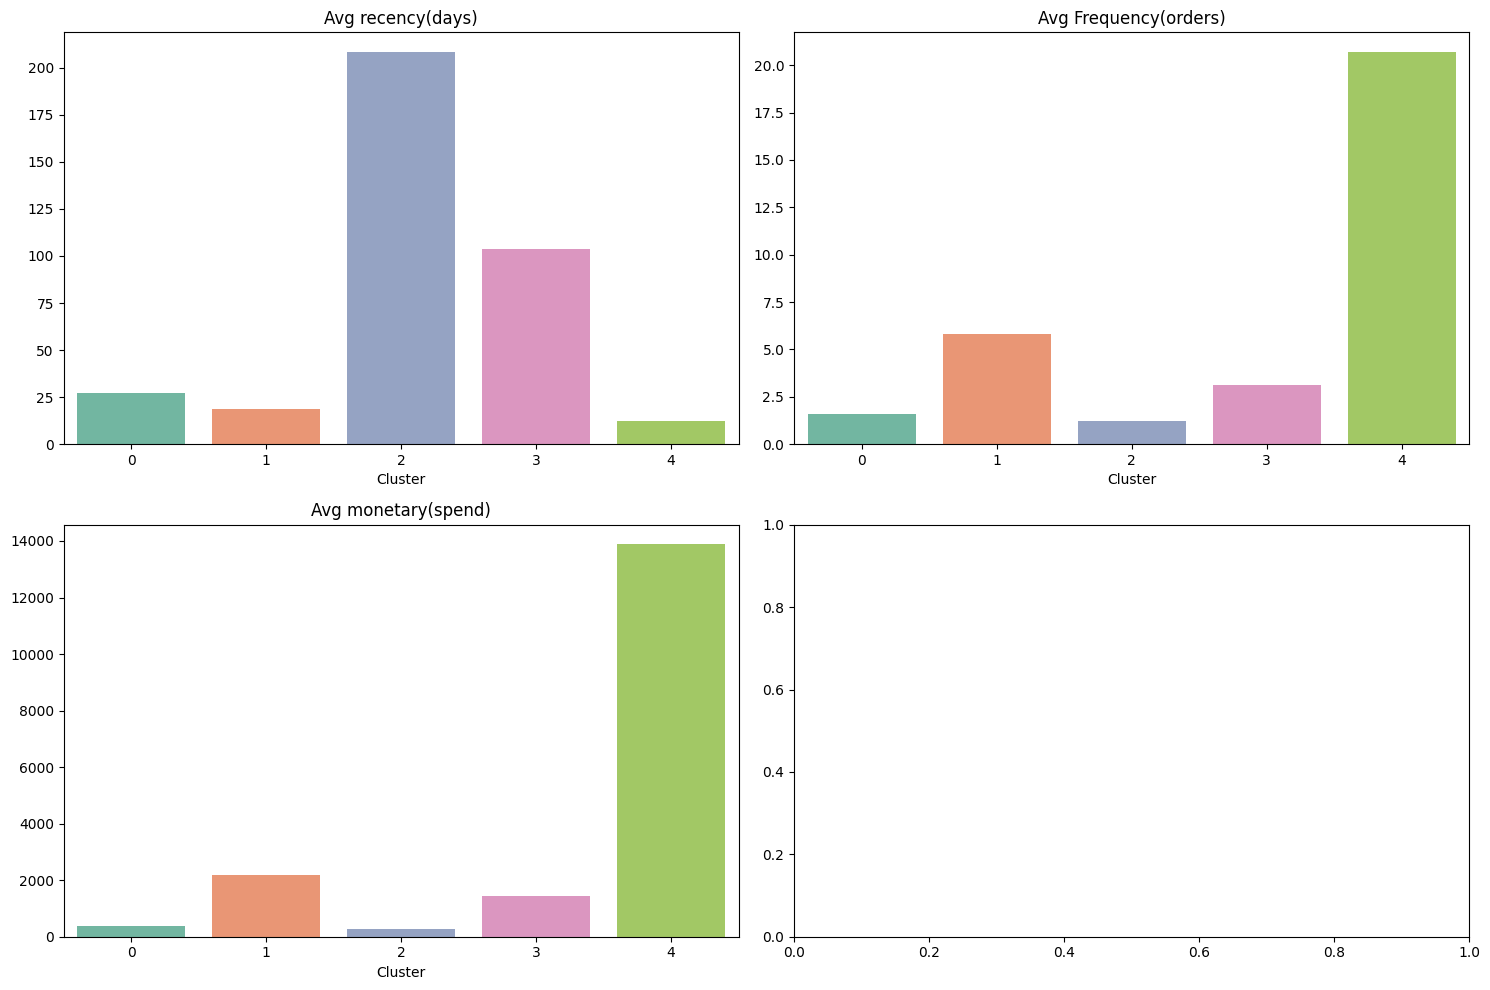

In [79]:
fig,axes = plt.subplots(2,2, figsize = (15,10))
axes = axes.flatten()
metrics = ['recency', 'freq', 'monetary']
title = ['Avg recency(days)', 'Avg Frequency(orders)', 'Avg monetary(spend)']
for ax, cols, title in zip(axes,metrics,title):
  sns.barplot(x =profile.index, y = profile[cols], palette='Set2', ax = ax)
  ax.set_title(title)
  ax.set_xlabel('Cluster')
  ax.set_ylabel("")
plt.tight_layout()
plt.show()



<Figure size 640x480 with 0 Axes>

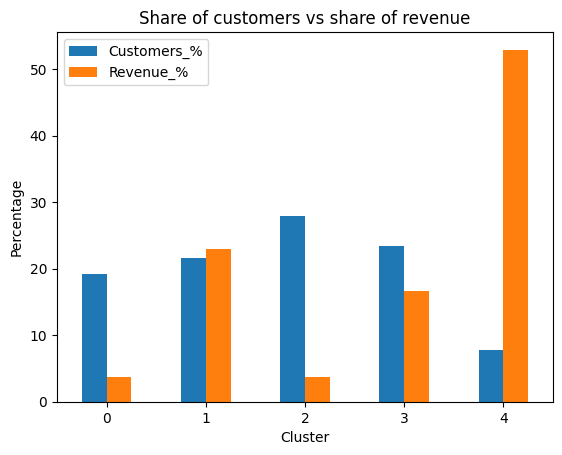

In [80]:
share = pd.DataFrame({
    "Customers_%": (profile["cout"] / profile["cout"].sum() * 100),
    "Revenue_%": profile["Revenu_Share"],
})
plt.figure()
share.plot(kind = 'bar')
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.title("Share of customers vs share of revenue")
plt.xticks(rotation=0)
plt.show()

---
###DBSCAN


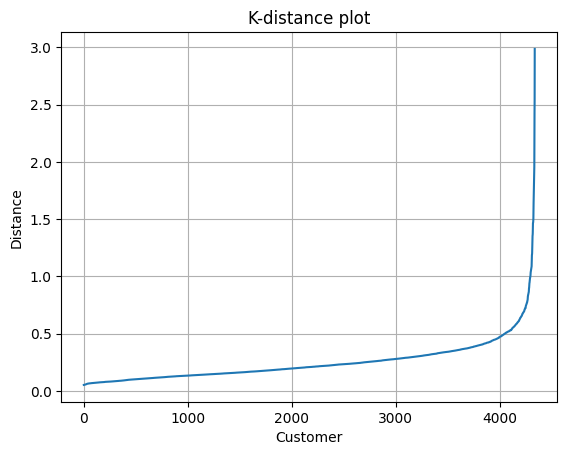

In [98]:
nn = NearestNeighbors(n_neighbors = 15).fit(rfm_scaled)
distance,_= nn.kneighbors(rfm_scaled)
k_dist = np.sort(distance[:,-1])

plt.figure()
plt.plot(k_dist)
plt.xlabel("Customer")
plt.ylabel("Distance")
plt.title("K-distance plot")
plt.grid(True)
plt.show()

In [99]:
dbscan = bd(eps = 0.5, min_samples = 15)
rfm['DBSCAN_CLUSTER']=dbscan.fit_predict(rfm_scaled)
print(rfm['DBSCAN_CLUSTER'].value_counts())

DBSCAN_CLUSTER
 0    2761
 1    1471
-1     106
Name: count, dtype: int64


In [100]:
profile_db = rfm.groupby('DBSCAN_CLUSTER').agg(
    recency = ('recency', 'mean'),
    freq = ('Freq', 'mean'),
    monetary = ('Monetary', 'mean'),
    cout =  ("CustomerID", 'count'),
    total_revenue = ("Monetary", "sum"),
).round(1)
profile_db["Revenu_Share"] = (profile_db['total_revenue']/profile_db['total_revenue'].sum() *100).round(3)
profile_db

,recency,freq,monetary,cout,total_revenue,Revenu_Share
DBSCAN_CLUSTER,,,,,,
-1,62.0,25.5,29403.0,106,3116718.8,35.070
0,59.2,5.2,1906.8,2761,5264691.8,59.239
1,157.4,1.0,343.8,1471,505798.3,5.691


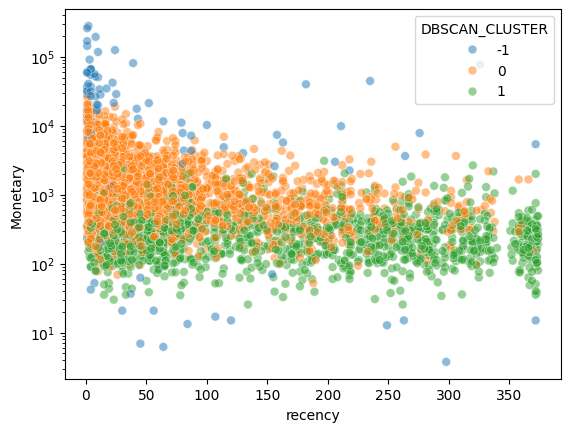

In [102]:
plt.figure()
sns.scatterplot(
    x = 'recency',
    y = 'Monetary',
    hue = 'DBSCAN_CLUSTER',
    data = rfm,
    palette = 'tab10',
    s = 40,
    alpha = 0.5
)
plt.yscale("log")
plt.show()